In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, mean_squared_error, r2_score, classification_report, confusion_matrix, accuracy_score, roc_auc_score
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10,6)

In [15]:
#Carregar dataset original 
life = pd.read_csv('data/Life_expectancy.csv')
suicide = pd.read_csv('data/Suicide_Rate.csv')

print(f"Life:{life.shape} | Suicide: {suicide.shape}")

#trocar tipo de dado do atributo(GDP)
suicide['GDP per capita'] = suicide['GDP per capita'].str.replace(',','').astype(float)

#Juntar os dois datasets e criar features
df = pd.merge(life, suicide, on='Country', how='inner')
print(f"Final após merge: {df.shape}") # (132, 7)

df['Life Expectancy Avg'] = (df['Life Expectancy (years) - Men'] + df['Life Expectancy (years) - Women']) / 2
df['Gender Gap'] = df['Life Expectancy (years) - Women'] - df['Life Expectancy (years) - Men']

df.to_csv('dataset_completo.csv', index=False)

Life:(142, 5) | Suicide: (140, 3)
Final após merge: (132, 7)


In [16]:
df = pd.read_csv('dataset_completo.csv')

In [17]:
# --- Life_expectancy.csv ---
print("LIFE", life.shape) 
display(life.head(3))
print(life.info())
print(f"Nulos:\n{life.isnull().sum()}")
print(f"Duplicados: {life.duplicated().sum()}")
# --- Suicide_Rate.csv ---
print("\nSUICIDE", suicide.shape) 
display(suicide.head(3))
print(suicide.info())
print(f"GDP sujo: {suicide['GDP per capita'].iloc[0]} - tipo {type(suicide['GDP per capita'].iloc[0])}")
# --- Completo após merge ---
print("\nCOMPLETO", df.shape) 
display(df.head(3))

LIFE (142, 5)


,Country,Life Expectancy (years) - Men,Life Expectancy (years) - Women,Happiness Score,Fertility Rate (births per woman)
0,Afghanistan,60.6,68.2,3.794,4.7
1,Albania,74.8,81.3,4.959,1.7
2,Algeria,73.3,78.9,5.605,2.9


<class 'pandas.DataFrame'>
RangeIndex: 142 entries, 0 to 141
Data columns (total 5 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Country                            142 non-null    str    
 1   Life Expectancy (years) - Men      142 non-null    float64
 2   Life Expectancy (years) - Women    142 non-null    float64
 3   Happiness Score                    142 non-null    float64
 4   Fertility Rate (births per woman)  142 non-null    float64
dtypes: float64(4), str(1)
memory usage: 6.8 KB
None
Nulos:
Country                              0
Life Expectancy (years) - Men        0
Life Expectancy (years) - Women      0
Happiness Score                      0
Fertility Rate (births per woman)    0
dtype: int64
Duplicados: 0

SUICIDE (140, 3)


,Country,GDP per capita,Suicide rate
0,Afghanistan,1105.0,20.6
1,Albania,4932.0,32.4
2,Algeria,4534.0,15.6


<class 'pandas.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country         140 non-null    str    
 1   GDP per capita  140 non-null    float64
 2   Suicide rate    140 non-null    float64
dtypes: float64(2), str(1)
memory usage: 4.5 KB
None
GDP sujo: 1105.0 - tipo <class 'numpy.float64'>

COMPLETO (132, 9)


,Country,Life Expectancy (years) - Men,Life Expectancy (years) - Women,Happiness Score,Fertility Rate (births per woman),GDP per capita,Suicide rate,Life Expectancy Avg,Gender Gap
0,Afghanistan,60.6,68.2,3.794,4.7,1105.0,20.6,64.40,7.6
1,Albania,74.8,81.3,4.959,1.7,4932.0,32.4,78.05,6.5
2,Algeria,73.3,78.9,5.605,2.9,4534.0,15.6,76.10,5.6


In [18]:
df.describe().round(2)

,Life Expectancy (years) - Men,Life Expectancy (years) - Women,Happiness Score,Fertility Rate (births per woman),GDP per capita,Suicide rate,Life Expectancy Avg,Gender Gap
count,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00
mean,71.95,76.86,5.58,2.79,15267.14,15.85,74.40,4.92
std,6.83,6.32,1.08,1.40,20845.45,5.45,6.55,1.18
min,52.90,55.60,3.35,1.30,463.00,9.60,54.25,2.10
25%,66.65,72.00,4.73,1.70,2161.75,12.50,69.24,4.00
50%,73.40,78.30,5.64,2.30,5811.50,14.35,76.05,5.00
75%,76.43,81.50,6.44,3.42,19373.25,17.60,78.80,5.70
max,84.00,89.50,7.77,7.60,118287.00,39.70,86.75,7.60


In [19]:
# Mostra assimetria de forma clara
for col in df.select_dtypes(include='float64').columns:
    print(f"{col}: Média {df[col].mean():.2f} | Mediana {df[col].median():.2f}")

Life Expectancy (years) - Men: Média 71.95 | Mediana 73.40
Life Expectancy (years) - Women: Média 76.86 | Mediana 78.30
Happiness Score: Média 5.58 | Mediana 5.64
Fertility Rate (births per woman): Média 2.79 | Mediana 2.30
GDP per capita: Média 15267.14 | Mediana 5811.50
Suicide rate: Média 15.85 | Mediana 14.35
Life Expectancy Avg: Média 74.40 | Mediana 76.05
Gender Gap: Média 4.92 | Mediana 5.00


                                   Life Expectancy Avg  Happiness Score  \
Life Expectancy Avg                               1.00             0.89   
Happiness Score                                   0.89             1.00   
Fertility Rate (births per woman)                -0.85            -0.76   
GDP per capita                                    0.66             0.75   
Suicide rate                                      0.08             0.01   
Gender Gap                                       -0.43            -0.44   

                                   Fertility Rate (births per woman)  \
Life Expectancy Avg                                            -0.85   
Happiness Score                                                -0.76   
Fertility Rate (births per woman)                               1.00   
GDP per capita                                                 -0.46   
Suicide rate                                                   -0.30   
Gender Gap                                

Text(0.5, 1.0, 'Correlação - 132 países')

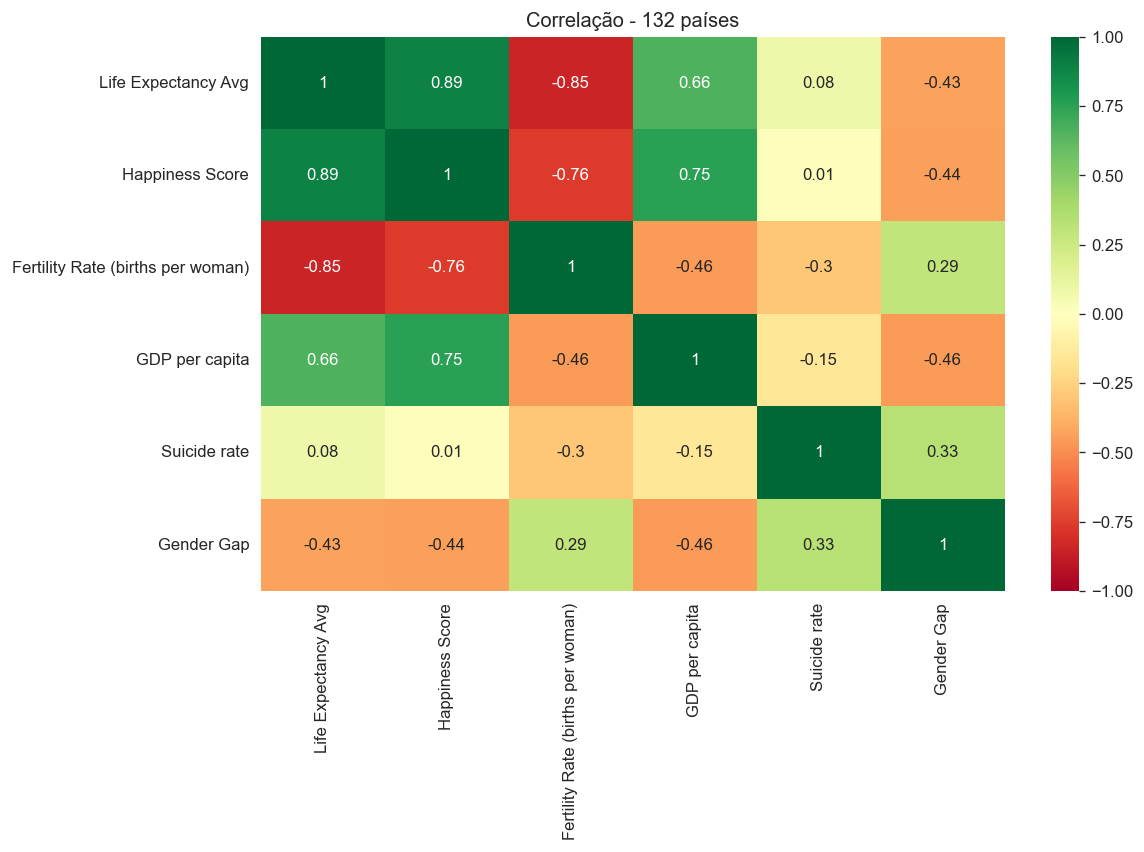

In [20]:
cols = ['Life Expectancy Avg','Happiness Score','Fertility Rate (births per woman)',
        'GDP per capita','Suicide rate','Gender Gap']
corr = df[cols].corr().round(2)
print(corr)
# Heatmap
sns.heatmap(corr, annot=True, cmap='RdYlGn', vmin=-1, vmax=1, center=0)
plt.title('Correlação - 132 países')

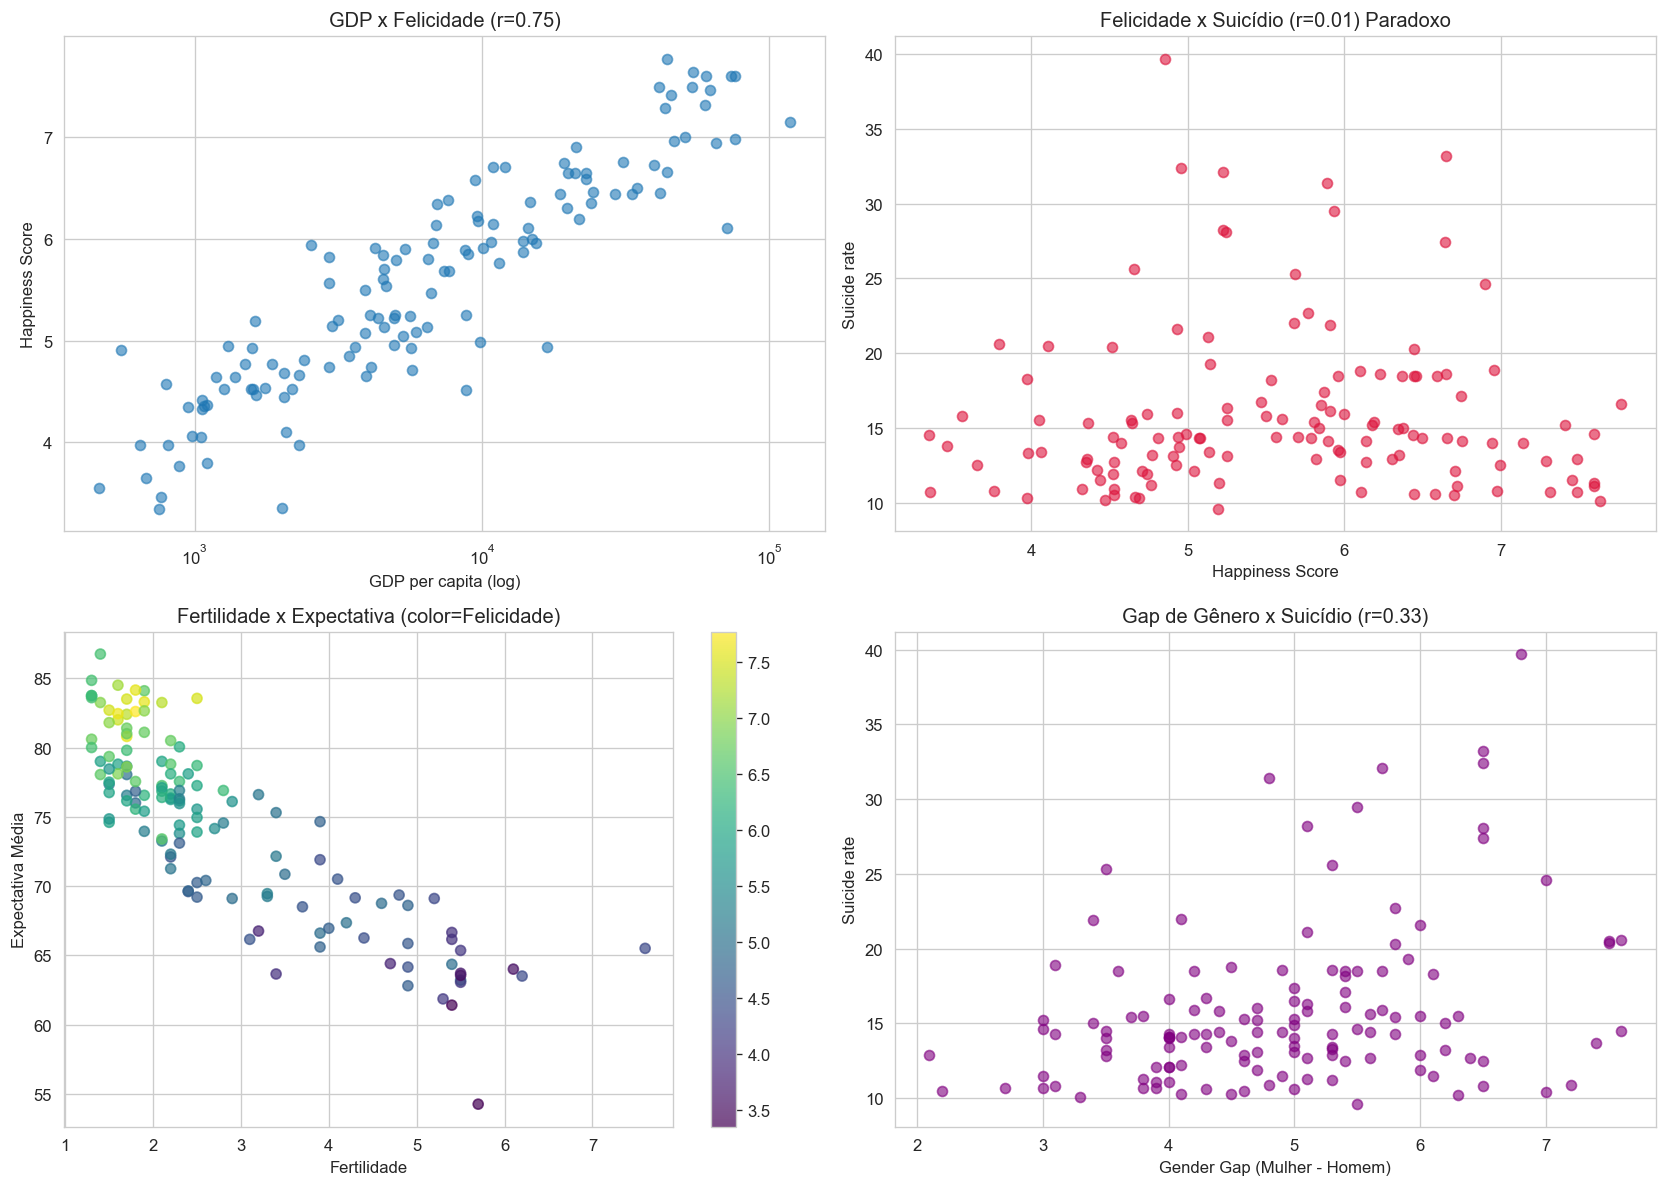

,Country,Life Expectancy (years) - Men,Life Expectancy (years) - Women,Happiness Score,Fertility Rate (births per woman),GDP per capita,Suicide rate,Life Expectancy Avg,Gender Gap
23,Brazil,72.9,78.2,6.226,1.8,9581.0,18.6,75.55,5.3


In [21]:
# 4 scatter plots principais
fig, axes = plt.subplots(2,2, figsize=(14,10))

# 1 - PIB log x Felicidade
axes[0,0].scatter(df['GDP per capita'], df['Happiness Score'], alpha=0.6)
axes[0,0].set_xscale('log')
axes[0,0].set_xlabel('GDP per capita (log)')
axes[0,0].set_ylabel('Happiness Score')
axes[0,0].set_title('GDP x Felicidade (r=0.75)')

# 2 - Felicidade x Suicidio
axes[0,1].scatter(df['Happiness Score'], df['Suicide rate'], alpha=0.6, color='crimson')
axes[0,1].set_xlabel('Happiness Score')
axes[0,1].set_ylabel('Suicide rate')
axes[0,1].set_title('Felicidade x Suicídio (r=0.01) Paradoxo')

# 3 - Fertilidade x Expectativa colorido por felicidade
sc = axes[1,0].scatter(df['Fertility Rate (births per woman)'], df['Life Expectancy Avg'], 
                       c=df['Happiness Score'], cmap='viridis', alpha=0.7)
axes[1,0].set_xlabel('Fertilidade')
axes[1,0].set_ylabel('Expectativa Média')
axes[1,0].set_title('Fertilidade x Expectativa (color=Felicidade)')
plt.colorbar(sc, ax=axes[1,0])

# 4 - Gender Gap x Suicidio
axes[1,1].scatter(df['Gender Gap'], df['Suicide rate'], alpha=0.6, color='purple')
axes[1,1].set_xlabel('Gender Gap (Mulher - Homem)')
axes[1,1].set_ylabel('Suicide rate')
axes[1,1].set_title('Gap de Gênero x Suicídio (r=0.33)')

plt.tight_layout()
plt.show()

# Exemplo Brasil
df[df['Country']=='Brazil']


k=2: silhueta=0.412
k=3: silhueta=0.386
k=4: silhueta=0.389
k=5: silhueta=0.334
k=6: silhueta=0.322
k=7: silhueta=0.260
k=8: silhueta=0.257


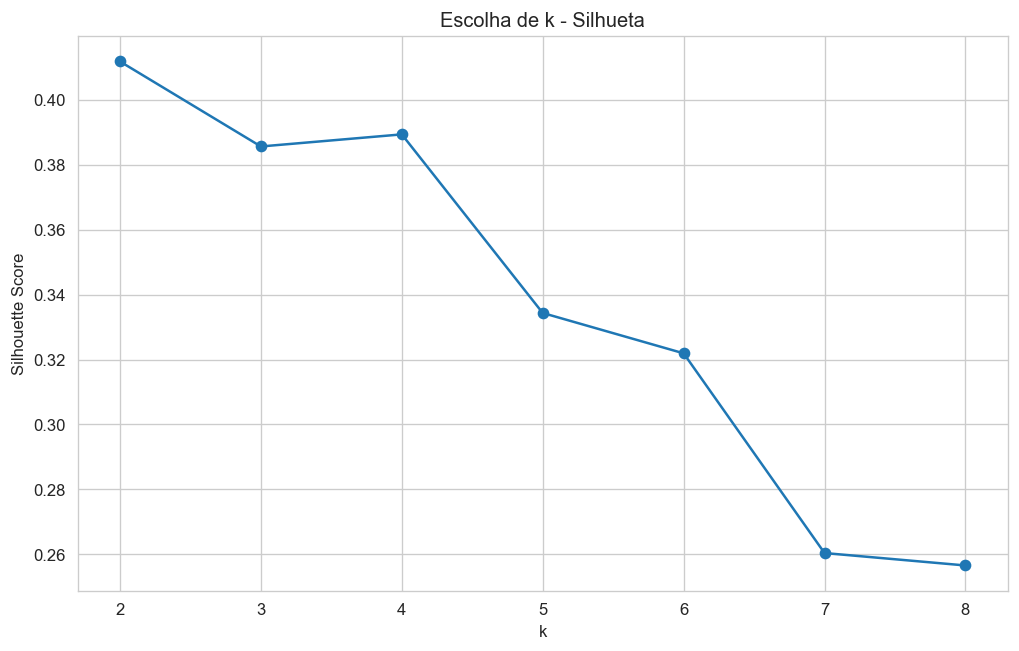

In [22]:
# Clustering - escolher k
features = ['Life Expectancy (years) - Men','Life Expectancy (years) - Women',
            'Happiness Score','Fertility Rate (births per woman)',
            'GDP per capita','Gender Gap','Life Expectancy Avg','Suicide rate']

X = df[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Silhueta para k 2-8
scores = {}
for k in range(2,9):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels)
    print(f"k={k}: silhueta={scores[k]:.3f}")

# Plot silhueta
plt.figure()
plt.plot(list(scores.keys()), list(scores.values()), marker='o')
plt.xlabel('k')
plt.ylabel('Silhouette Score')
plt.title('Escolha de k - Silhueta')
plt.grid(True)
plt.show()


PCA explica 84.2% da variância


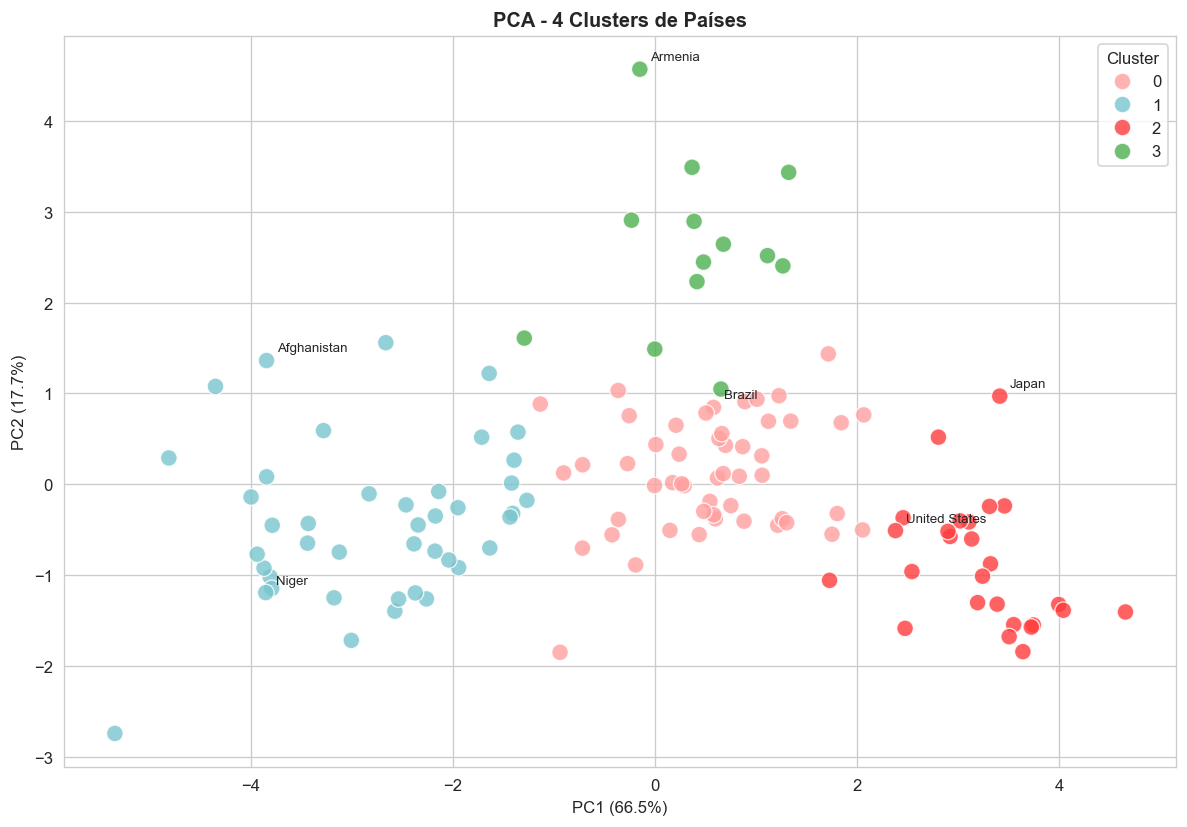

,Life Expectancy (years) - Men,Life Expectancy (years) - Women,Happiness Score,Fertility Rate (births per woman),GDP per capita,Suicide rate,Gender Gap,Country
Cluster,,,,,,,,
0,74.06,78.84,5.79,2.23,8925.12,15.32,4.77,51
1,63.62,69.18,4.41,4.47,2369.74,13.87,5.56,42
2,80.73,84.44,7.02,1.69,51574.69,13.37,3.71,26
3,72.98,78.78,5.66,1.75,9200.77,29.25,5.81,13


In [23]:
# k=4 escolhido - melhor interpretabilidade
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# PCA para visualizar
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"PCA explica {pca.explained_variance_ratio_.sum()*100:.1f}% da variância")

plt.figure(figsize=(10,7))
palette_list = ['#FF9F9F','#7AC5CD','#FF3B3B','#4CAF50']
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=df['Cluster'], palette=palette_list, s=100, alpha=0.8)
plt.title('PCA - 4 Clusters de Países', fontweight='bold')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')

# Anotar alguns países
for i, country in enumerate(df['Country']):
    if country in ['Brazil','United States','Japan','Afghanistan','Armenia','Switzerland','Niger']:
        plt.text(X_pca[i,0]+0.1, X_pca[i,1]+0.1, country, fontsize=8)

plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

# Perfil dos clusters
df.groupby('Cluster').agg({
    'Life Expectancy (years) - Men':'mean',
    'Life Expectancy (years) - Women':'mean',
    'Happiness Score':'mean',
    'Fertility Rate (births per woman)':'mean',
    'GDP per capita':'mean',
    'Suicide rate':'mean',
    'Gender Gap':'mean',
    'Country':'count'
}).round(2)


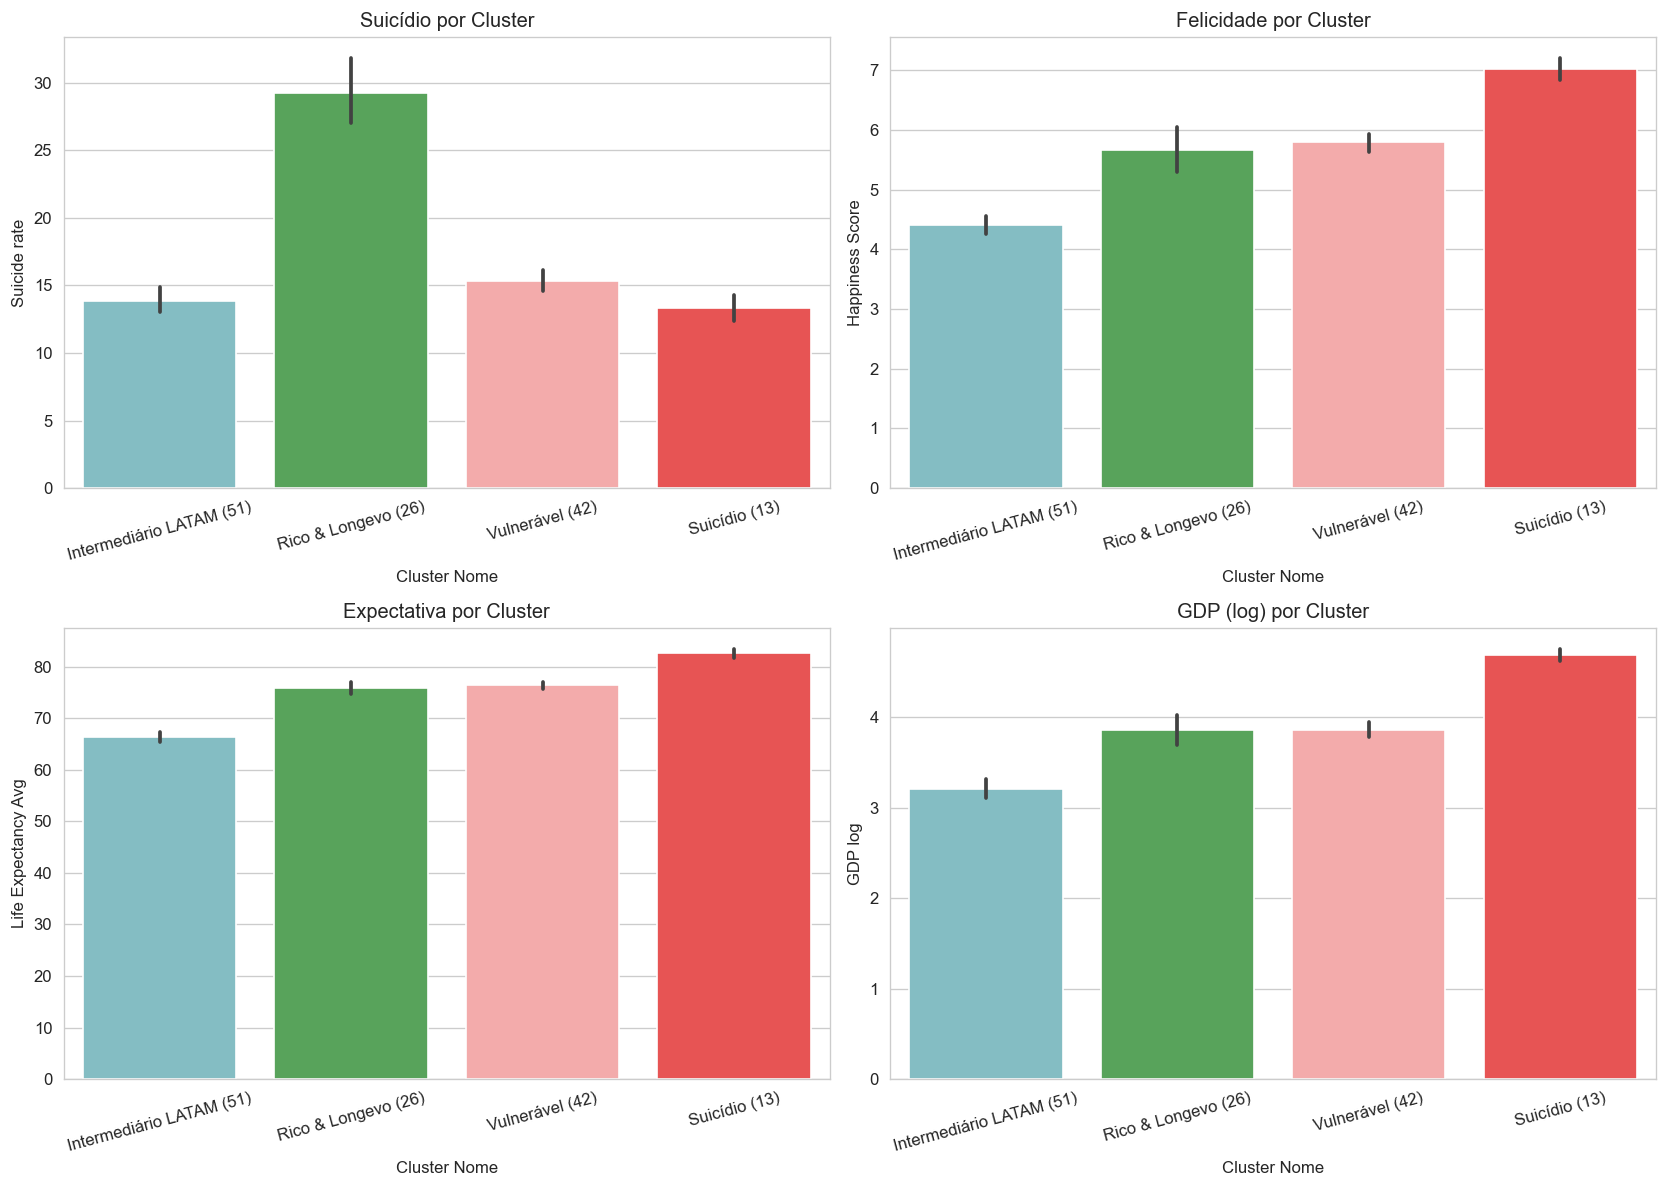

In [25]:
cluster_names = {0:'Vulnerável (42)', 1:'Intermediário LATAM (51)', 2:'Suicídio (13)', 3:'Rico & Longevo (26)'}
df['Cluster Nome'] = df['Cluster'].map(cluster_names)

palette_dict = { 'Vulnerável (42)':'#FF9F9F', 'Intermediário LATAM (51)':'#7AC5CD', 'Suicídio (13)':'#FF3B3B', 'Rico & Longevo (26)':'#4CAF50' }

fig, axes = plt.subplots(2,2, figsize=(14,10))

sns.barplot(data=df, x='Cluster Nome', y='Suicide rate', ax=axes[0,0], palette=palette_dict, hue='Cluster Nome', legend=False)
axes[0,0].set_title('Suicídio por Cluster')
axes[0,0].tick_params(axis='x', rotation=15)

sns.barplot(data=df, x='Cluster Nome', y='Happiness Score', ax=axes[0,1], palette=palette_dict, hue='Cluster Nome', legend=False)
axes[0,1].set_title('Felicidade por Cluster')
axes[0,1].tick_params(axis='x', rotation=15)

sns.barplot(data=df, x='Cluster Nome', y='Life Expectancy Avg', ax=axes[1,0], palette=palette_dict, hue='Cluster Nome', legend=False)
axes[1,0].set_title('Expectativa por Cluster')
axes[1,0].tick_params(axis='x', rotation=15)

# GDP em log pra visualização
df['GDP log'] = np.log10(df['GDP per capita'])
sns.barplot(data=df, x='Cluster Nome', y='GDP log', ax=axes[1,1], palette=palette_dict, hue='Cluster Nome', legend=False)
axes[1,1].set_title('GDP (log) por Cluster')
axes[1,1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

df.to_csv('dataset_com_cluster.csv', index=False)


=== Holdout 25% ===
Linear Regression -> RMSE: 3.96 | R²: -0.28
Random Forest -> RMSE: 3.35 | R²: 0.08

=== CV 5-fold ===
Random Forest R² CV: 0.25 (+/- 0.28)

Importância:
                             feature  importance
5                         Gender Gap    0.248075
3  Fertility Rate (births per woman)    0.236535
4                     GDP per capita    0.161313
0      Life Expectancy (years) - Men    0.130832
6                Life Expectancy Avg    0.081243
2                    Happiness Score    0.074998
1    Life Expectancy (years) - Women    0.067005


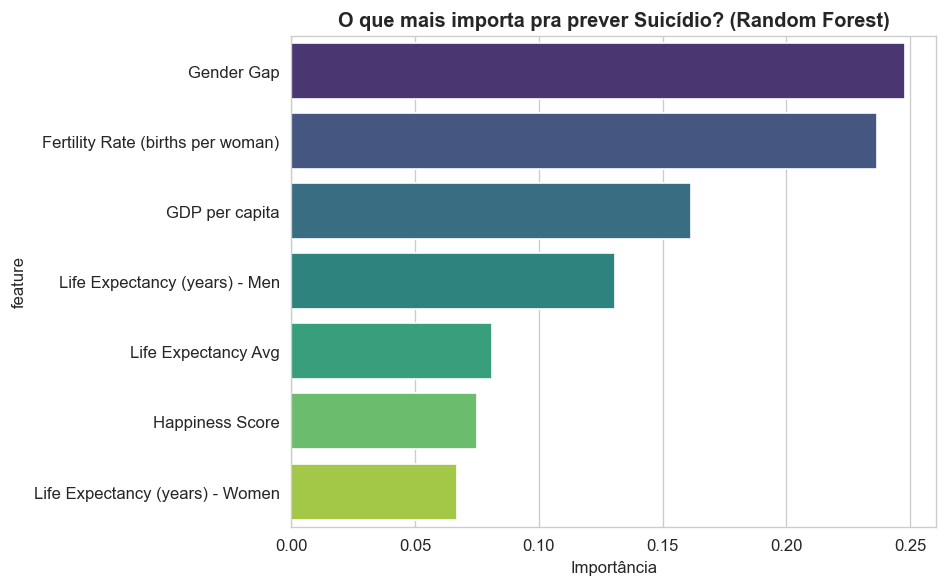

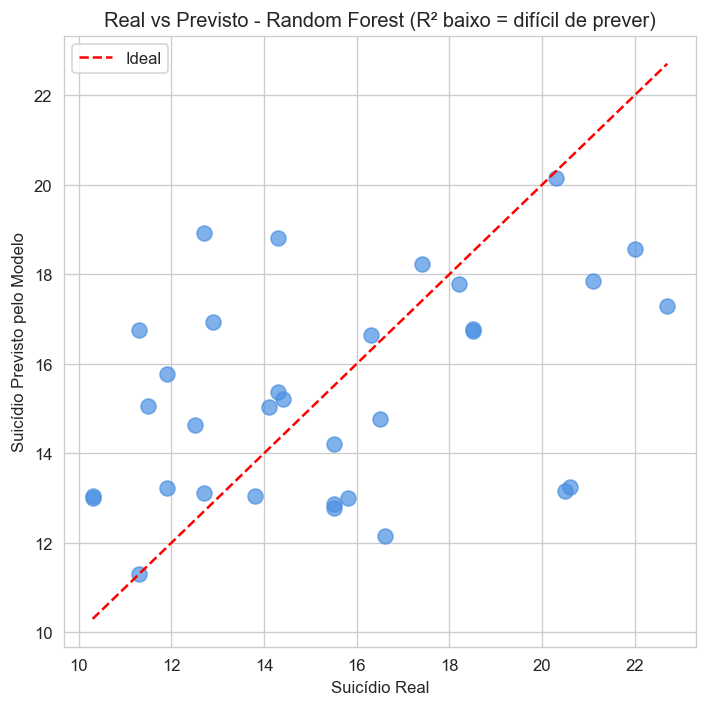

In [26]:
# --- REGRESSÃO - Prever Suicídio (número exato) ---

# ATENÇÃO: Não usar Cluster como feature - vazamento de dados pois cluster foi criado COM suicídio
features_reg = ['Life Expectancy (years) - Men','Life Expectancy (years) - Women',
            'Happiness Score','Fertility Rate (births per woman)',
            'GDP per capita','Gender Gap','Life Expectancy Avg']

X = df[features_reg]
y = df['Suicide rate']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Modelos
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

rf = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

def eval_model(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name} -> RMSE: {rmse:.2f} | R²: {r2:.2f}")

print("=== Holdout 25% ===")
eval_model("Linear Regression", y_test, y_pred_lr)
eval_model("Random Forest", y_test, y_pred_rf)

print("\n=== CV 5-fold ===")
cv_rf = cross_val_score(rf, X, y, cv=5, scoring='r2')
print(f"Random Forest R² CV: {cv_rf.mean():.2f} (+/- {cv_rf.std():.2f})")

# Importância
importance = pd.DataFrame({
    'feature': features_reg,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print("\nImportância:")
print(importance)

# PLOT 1 - Importância (ESSE FALTAVA NO SEU NOTEBOOK)
plt.figure(figsize=(8,5))
sns.barplot(data=importance, x='importance', y='feature', hue='feature', palette='viridis', legend=False)
plt.title('O que mais importa pra prever Suicídio? (Random Forest)', fontweight='bold')
plt.xlabel('Importância')
plt.tight_layout()
plt.show()

# PLOT 2 - Real vs Previsto (ESSE FALTAVA)
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_rf, alpha=0.7, s=80, color='#4A90E2')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Ideal')
plt.xlabel('Suicídio Real')
plt.ylabel('Suicídio Previsto pelo Modelo')
plt.title('Real vs Previsto - Random Forest (R² baixo = difícil de prever)')
plt.legend()
plt.tight_layout()
plt.show()

Mediana: 14.35
Baixo: 66 | Alto: 66

Acurácia: 0.76
AUC: 0.83
              precision    recall  f1-score   support

       Baixo       0.70      0.94      0.80        17
        Alto       0.90      0.56      0.69        16

    accuracy                           0.76        33
   macro avg       0.80      0.75      0.75        33
weighted avg       0.79      0.76      0.75        33



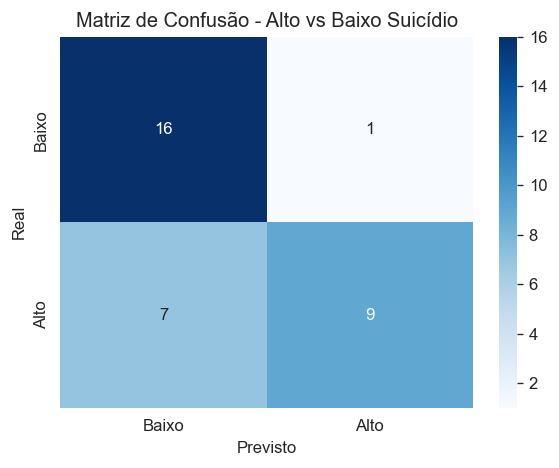

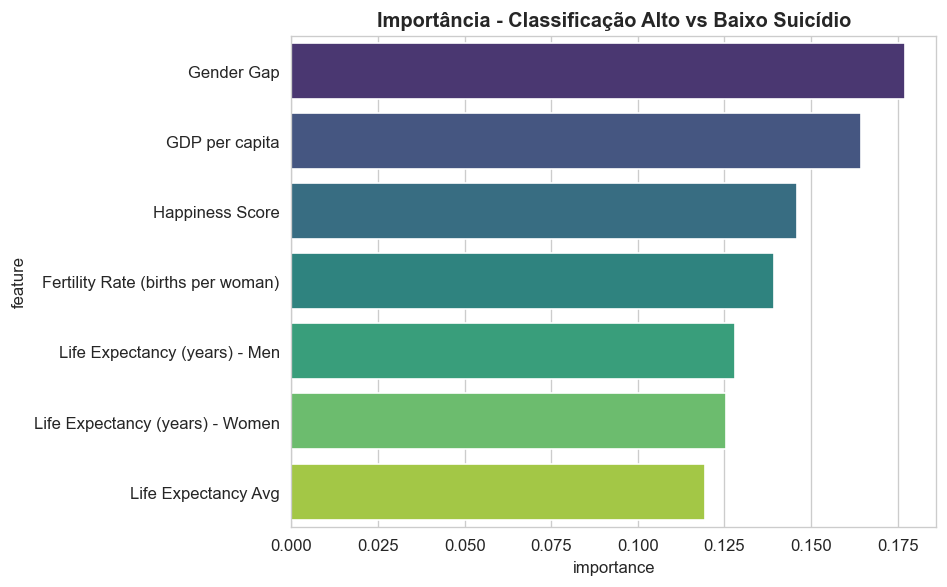


BRASIL - Taxa 18.6 - Prob Alto Suicídio: 56.9%


In [27]:
# --- CLASSIFICAÇÃO - Alto vs Baixo Suicídio ---

# Criar classe balanceada usando mediana
median_suicide = df['Suicide rate'].median()
df['Suicide_High'] = (df['Suicide rate'] > median_suicide).astype(int)

print(f"Mediana: {median_suicide:.2f}")
print(f"Baixo: {(df['Suicide_High']==0).sum()} | Alto: {(df['Suicide_High']==1).sum()}")

features_clf = ['Life Expectancy (years) - Men','Life Expectancy (years) - Women',
                'Happiness Score','Fertility Rate (births per woman)',
                'GDP per capita','Gender Gap','Life Expectancy Avg']

X = df[features_clf]
y = df['Suicide_High']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

rf_clf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
rf_clf.fit(X_train, y_train)
y_pred = rf_clf.predict(X_test)
y_proba = rf_clf.predict_proba(X_test)[:,1]

print(f"\nAcurácia: {accuracy_score(y_test, y_pred):.2f}")
print(f"AUC: {roc_auc_score(y_test, y_proba):.2f}")
print(classification_report(y_test, y_pred, target_names=['Baixo','Alto']))

# PLOT 1 - Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Baixo','Alto'], yticklabels=['Baixo','Alto'])
plt.title('Matriz de Confusão - Alto vs Baixo Suicídio')
plt.ylabel('Real')
plt.xlabel('Previsto')
plt.tight_layout()
plt.show()

# PLOT 2 - Importância classificação
importance_clf = pd.DataFrame({
    'feature': features_clf,
    'importance': rf_clf.feature_importances_
}).sort_values('importance', ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(data=importance_clf, x='importance', y='feature', hue='feature', palette='viridis', legend=False)
plt.title('Importância - Classificação Alto vs Baixo Suicídio', fontweight='bold')
plt.tight_layout()
plt.show()

# Brasil
br = df[df['Country']=='Brazil']
prob = rf_clf.predict_proba(br[features_clf])[0]
print(f"\nBRASIL - Taxa {br['Suicide rate'].values[0]} - Prob Alto Suicídio: {prob[1]:.1%}")

## Conclusão

- **EDA:** Correlação Felicidade x Suicídio = 0.01 (paradoxo). Felicidade não protege.
- **Clustering:** 4 grupos - Vulnerável (42), Intermediário LATAM (51) com Brasil, Suicídio (13) ex-URSS com taxa 29.25, Rico & Longevo (26)
- **Regressão:** R² 0.08 (holdout) e 0.25 (CV) - suicídio é difícil de prever só com indicadores macro. Gender Gap e Fertilidade são mais importantes que PIB e Felicidade.
- **Classificação:** 76% acurácia e 83% AUC ao classificar alto/baixo, muito melhor que regressão.
